# Weather Data Analysis: Exploring Temporal Patterns

## Import Libraries

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
os.makedirs('screenshots', exist_ok=True)

## Load the Dataset



In [2]:
csv_path = 'weatherHistory.csv'
if not os.path.exists(csv_path):
    raise FileNotFoundError(
        'weatherHistory.csv was not found. Download it from the Kaggle URL in README.md, '
        'extract the archive, and place the CSV beside this notebook.'
    )

weather = pd.read_csv(csv_path)
weather.head()

,Formatted Date,Summary,Precip Type,Temperature (C),Apparent Temperature (C),Humidity,Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Loud Cover,Pressure (millibars),Daily Summary
0,2006-04-01 00:00:00.000 +0200,Partly Cloudy,rain,9.472222,7.388889,0.89,14.1197,251.0,15.8263,0.0,1015.13,Partly cloudy throughout the day.
1,2006-04-01 01:00:00.000 +0200,Partly Cloudy,rain,9.355556,7.227778,0.86,14.2646,259.0,15.8263,0.0,1015.63,Partly cloudy throughout the day.
2,2006-04-01 02:00:00.000 +0200,Mostly Cloudy,rain,9.377778,9.377778,0.89,3.9284,204.0,14.9569,0.0,1015.94,Partly cloudy throughout the day.
3,2006-04-01 03:00:00.000 +0200,Partly Cloudy,rain,8.288889,5.944444,0.83,14.1036,269.0,15.8263,0.0,1016.41,Partly cloudy throughout the day.
4,2006-04-01 04:00:00.000 +0200,Mostly Cloudy,rain,8.755556,6.977778,0.83,11.0446,259.0,15.8263,0.0,1016.51,Partly cloudy throughout the day.


## Inspect the Dataset

In [3]:
print('First five rows:')
display(weather.head())
print('Last five rows:')
display(weather.tail())
print('Shape:', weather.shape)
print('Column names:', weather.columns.tolist())
print('Data types:')
print(weather.dtypes)
print('Information:')
weather.info()
display(weather.describe())

First five rows:


,Formatted Date,Summary,Precip Type,Temperature (C),Apparent Temperature (C),Humidity,Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Loud Cover,Pressure (millibars),Daily Summary
0,2006-04-01 00:00:00.000 +0200,Partly Cloudy,rain,9.472222,7.388889,0.89,14.1197,251.0,15.8263,0.0,1015.13,Partly cloudy throughout the day.
1,2006-04-01 01:00:00.000 +0200,Partly Cloudy,rain,9.355556,7.227778,0.86,14.2646,259.0,15.8263,0.0,1015.63,Partly cloudy throughout the day.
2,2006-04-01 02:00:00.000 +0200,Mostly Cloudy,rain,9.377778,9.377778,0.89,3.9284,204.0,14.9569,0.0,1015.94,Partly cloudy throughout the day.
3,2006-04-01 03:00:00.000 +0200,Partly Cloudy,rain,8.288889,5.944444,0.83,14.1036,269.0,15.8263,0.0,1016.41,Partly cloudy throughout the day.
4,2006-04-01 04:00:00.000 +0200,Mostly Cloudy,rain,8.755556,6.977778,0.83,11.0446,259.0,15.8263,0.0,1016.51,Partly cloudy throughout the day.


Last five rows:


,Formatted Date,Summary,Precip Type,Temperature (C),Apparent Temperature (C),Humidity,Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Loud Cover,Pressure (millibars),Daily Summary
96448,2016-09-09 19:00:00.000 +0200,Partly Cloudy,rain,26.016667,26.016667,0.43,10.9963,31.0,16.1000,0.0,1014.36,Partly cloudy starting in the morning.
96449,2016-09-09 20:00:00.000 +0200,Partly Cloudy,rain,24.583333,24.583333,0.48,10.0947,20.0,15.5526,0.0,1015.16,Partly cloudy starting in the morning.
96450,2016-09-09 21:00:00.000 +0200,Partly Cloudy,rain,22.038889,22.038889,0.56,8.9838,30.0,16.1000,0.0,1015.66,Partly cloudy starting in the morning.
96451,2016-09-09 22:00:00.000 +0200,Partly Cloudy,rain,21.522222,21.522222,0.60,10.5294,20.0,16.1000,0.0,1015.95,Partly cloudy starting in the morning.
96452,2016-09-09 23:00:00.000 +0200,Partly Cloudy,rain,20.438889,20.438889,0.61,5.8765,39.0,15.5204,0.0,1016.16,Partly cloudy starting in the morning.


Shape: (96453, 12)
Column names: ['Formatted Date', 'Summary', 'Precip Type', 'Temperature (C)', 'Apparent Temperature (C)', 'Humidity', 'Wind Speed (km/h)', 'Wind Bearing (degrees)', 'Visibility (km)', 'Loud Cover', 'Pressure (millibars)', 'Daily Summary']
Data types:
Formatted Date               object
Summary                      object
Precip Type                  object
Temperature (C)             float64
Apparent Temperature (C)    float64
Humidity                    float64
Wind Speed (km/h)           float64
Wind Bearing (degrees)      float64
Visibility (km)             float64
Loud Cover                  float64
Pressure (millibars)        float64
Daily Summary                object
dtype: object
Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 96453 entries, 0 to 96452
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Formatted Date            96453 non-null  objec

,Temperature (C),Apparent Temperature (C),Humidity,Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Loud Cover,Pressure (millibars)
count,96453.000000,96453.000000,96453.000000,96453.000000,96453.000000,96453.000000,96453.0,96453.000000
mean,11.932678,10.855029,0.734899,10.810640,187.509232,10.347325,0.0,1003.235956
std,9.551546,10.696847,0.195473,6.913571,107.383428,4.192123,0.0,116.969906
min,-21.822222,-27.716667,0.000000,0.000000,0.000000,0.000000,0.0,0.000000
25%,4.688889,2.311111,0.600000,5.828200,116.000000,8.339800,0.0,1011.900000
50%,12.000000,12.000000,0.780000,9.965900,180.000000,10.046400,0.0,1016.450000
75%,18.838889,18.838889,0.890000,14.135800,290.000000,14.812000,0.0,1021.090000
max,39.905556,39.344444,1.000000,63.852600,359.000000,16.100000,0.0,1046.380000


## Check Data Quality

In [4]:
print('Missing values by column:')
print(weather.isna().sum())
print('Exact duplicate rows:', weather.duplicated().sum())
clean_weather = weather.copy()

Missing values by column:
Formatted Date                0
Summary                       0
Precip Type                 517
Temperature (C)               0
Apparent Temperature (C)      0
Humidity                      0
Wind Speed (km/h)             0
Wind Bearing (degrees)        0
Visibility (km)               0
Loud Cover                    0
Pressure (millibars)          0
Daily Summary                 0
dtype: int64
Exact duplicate rows: 24


## Prepare Time Features

In [5]:
clean_weather['Formatted Date'] = pd.to_datetime(clean_weather['Formatted Date'], utc=True)
clean_weather = clean_weather.sort_values('Formatted Date').reset_index(drop=True)
clean_weather['Year'] = clean_weather['Formatted Date'].dt.year
clean_weather['Month'] = clean_weather['Formatted Date'].dt.month
clean_weather[['Formatted Date', 'Year', 'Month']].head()

,Formatted Date,Year,Month
0,2005-12-31 23:00:00+00:00,2005,12
1,2006-01-01 00:00:00+00:00,2006,1
2,2006-01-01 01:00:00+00:00,2006,1
3,2006-01-01 02:00:00+00:00,2006,1
4,2006-01-01 03:00:00+00:00,2006,1


## Basic Exploratory Analysis

In [6]:
temperature_summary = clean_weather['Temperature (C)'].agg(['mean', 'min', 'max'])
average_humidity = clean_weather['Humidity'].mean()
print('Temperature summary (C):')
print(temperature_summary)
print(f'Average humidity: {average_humidity:.3f}')

numerical_columns = clean_weather.select_dtypes(include=np.number).columns
display(clean_weather[numerical_columns].describe())

monthly_temperature = clean_weather.groupby('Month')['Temperature (C)'].mean()
display(monthly_temperature)

Temperature summary (C):
mean    11.932678
min    -21.822222
max     39.905556
Name: Temperature (C), dtype: float64
Average humidity: 0.735


,Temperature (C),Apparent Temperature (C),Humidity,Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Loud Cover,Pressure (millibars),Year,Month
count,96453.000000,96453.000000,96453.000000,96453.000000,96453.000000,96453.000000,96453.0,96453.000000,96453.00000,96453.000000
mean,11.932678,10.855029,0.734899,10.810640,187.509232,10.347325,0.0,1003.235956,2011.00029,6.523001
std,9.551546,10.696847,0.195473,6.913571,107.383428,4.192123,0.0,116.969906,3.16216,3.448501
min,-21.822222,-27.716667,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,2005.00000,1.000000
25%,4.688889,2.311111,0.600000,5.828200,116.000000,8.339800,0.0,1011.900000,2008.00000,4.000000
50%,12.000000,12.000000,0.780000,9.965900,180.000000,10.046400,0.0,1016.450000,2011.00000,7.000000
75%,18.838889,18.838889,0.890000,14.135800,290.000000,14.812000,0.0,1021.090000,2014.00000,10.000000
max,39.905556,39.344444,1.000000,63.852600,359.000000,16.100000,0.0,1046.380000,2016.00000,12.000000


Month
1      0.815678
2      2.166880
3      6.914976
4     12.769200
5     16.874455
6     20.728510
7     22.965462
8     22.339134
9     17.503458
10    11.334119
11     6.587549
12     1.625086
Name: Temperature (C), dtype: float64

## Rolling Average

In [7]:
time_weather = clean_weather.set_index('Formatted Date')
time_weather['Temperature Rolling Average (C)'] = (
    time_weather['Temperature (C)'].rolling('30D', min_periods=1).mean()
)
time_weather[['Temperature (C)', 'Temperature Rolling Average (C)']].head()

,Temperature (C),Temperature Rolling Average (C)
Formatted Date,,
2005-12-31 23:00:00+00:00,0.577778,0.577778
2006-01-01 00:00:00+00:00,1.161111,0.869444
2006-01-01 01:00:00+00:00,1.666667,1.135185
2006-01-01 02:00:00+00:00,1.711111,1.279167
2006-01-01 03:00:00+00:00,1.183333,1.260000


## Visualizations

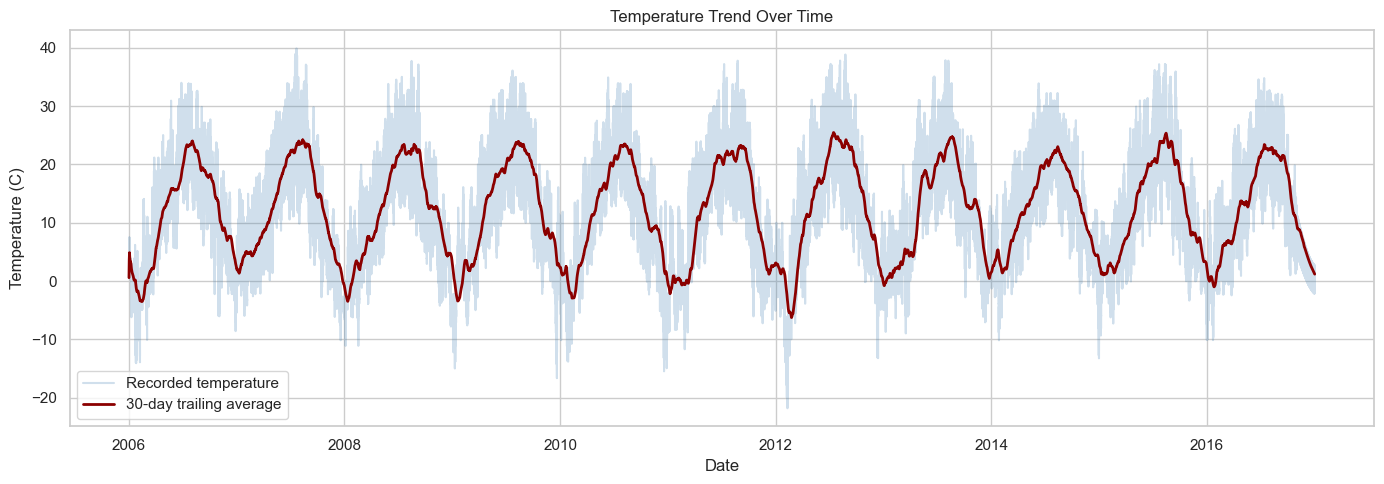

In [8]:
plt.figure(figsize=(14, 5))
plt.plot(time_weather.index, time_weather['Temperature (C)'], color='steelblue', alpha=0.25, label='Recorded temperature')
plt.plot(time_weather.index, time_weather['Temperature Rolling Average (C)'], color='darkred', linewidth=2, label='30-day trailing average')
plt.title('Temperature Trend Over Time')
plt.xlabel('Date')
plt.ylabel('Temperature (C)')
plt.legend()
plt.tight_layout()
plt.savefig('screenshots/temperature_trend.png', dpi=150)
plt.show()

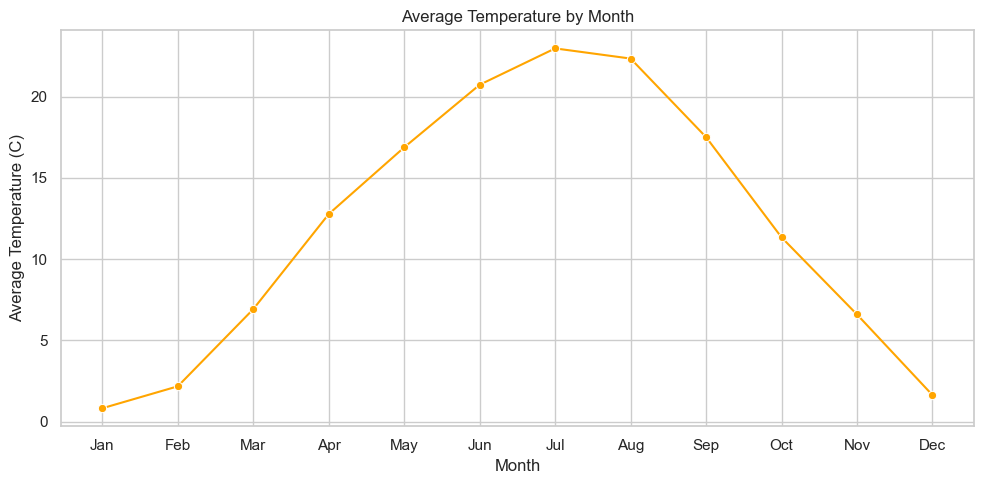

In [9]:
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
plt.figure(figsize=(10, 5))
sns.lineplot(x=monthly_temperature.index, y=monthly_temperature.values, marker='o', color='orange')
plt.title('Average Temperature by Month')
plt.xlabel('Month')
plt.ylabel('Average Temperature (C)')
plt.xticks(range(1, 13), month_names)
plt.tight_layout()
plt.savefig('screenshots/monthly_temperature.png', dpi=150)
plt.show()

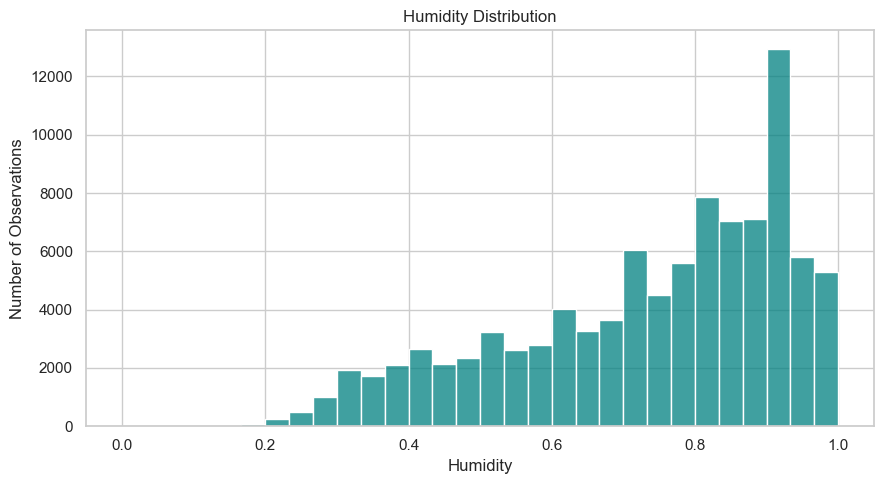

In [10]:
plt.figure(figsize=(9, 5))
sns.histplot(
    data=clean_weather,
    x='Humidity',
    bins=30,
    color='teal',
    edgecolor='white'
)
plt.title('Humidity Distribution')
plt.xlabel('Humidity')
plt.ylabel('Number of Observations')
plt.tight_layout()
plt.savefig('screenshots/humidity_distribution.png', dpi=150)
plt.show()

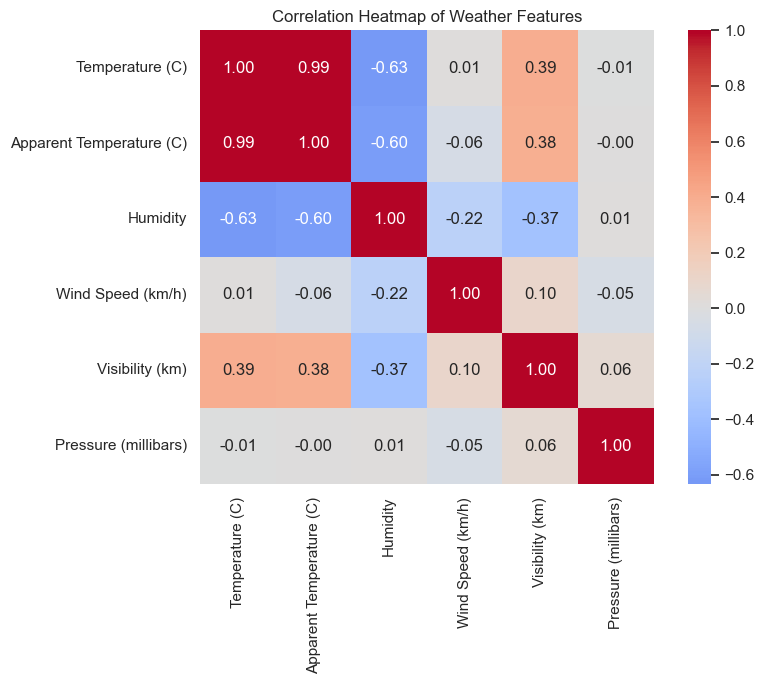

,Temperature (C),Apparent Temperature (C),Humidity,Wind Speed (km/h),Visibility (km),Pressure (millibars)
Temperature (C),1.000000,0.992629,-0.632255,0.008957,0.392847,-0.005447
Apparent Temperature (C),0.992629,1.000000,-0.602571,-0.056650,0.381718,-0.000219
Humidity,-0.632255,-0.602571,1.000000,-0.224951,-0.369173,0.005454
Wind Speed (km/h),0.008957,-0.056650,-0.224951,1.000000,0.100749,-0.049263
Visibility (km),0.392847,0.381718,-0.369173,0.100749,1.000000,0.059818
Pressure (millibars),-0.005447,-0.000219,0.005454,-0.049263,0.059818,1.000000


In [11]:
selected_features = ['Temperature (C)', 'Apparent Temperature (C)', 'Humidity', 'Wind Speed (km/h)', 'Visibility (km)', 'Pressure (millibars)']
correlation = clean_weather[selected_features].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(correlation, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)
plt.title('Correlation Heatmap of Weather Features')
plt.tight_layout()
plt.savefig('screenshots/correlation_heatmap.png', dpi=150)
plt.show()

correlation